# Layyana Junaid 23k0056
### Lab 3

### Tasks 1-4: Linear and Translation

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('image.png') 
if img is None:
    raise FileNotFoundError("Image not found, check the path")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  

h, w = img.shape[:2]
cx, cy = w / 2, h / 2
print(f"Image dimensions: {h} x {w}")
print(f"Center coordinates: ({cx}, {cy})")

Image dimensions: 1200 x 903
Center coordinates: (451.5, 600.0)


In [3]:
import matplotlib.pyplot as plt

def show(before, after, title="Result"):
    plt.figure(figsize=(10, 6))
    plt.subplot(1, 2, 1); plt.imshow(cv2.cvtColor(before, cv2.COLOR_BGR2RGB)); plt.title("Original"); plt.axis('off')
    plt.subplot(1, 2, 2); plt.imshow(cv2.cvtColor(after, cv2.COLOR_BGR2RGB)); plt.title(title); plt.axis('off')
    plt.show()

Scaling matrix:
 [[    3.     0.  -903.]
 [    0.     3. -1200.]]


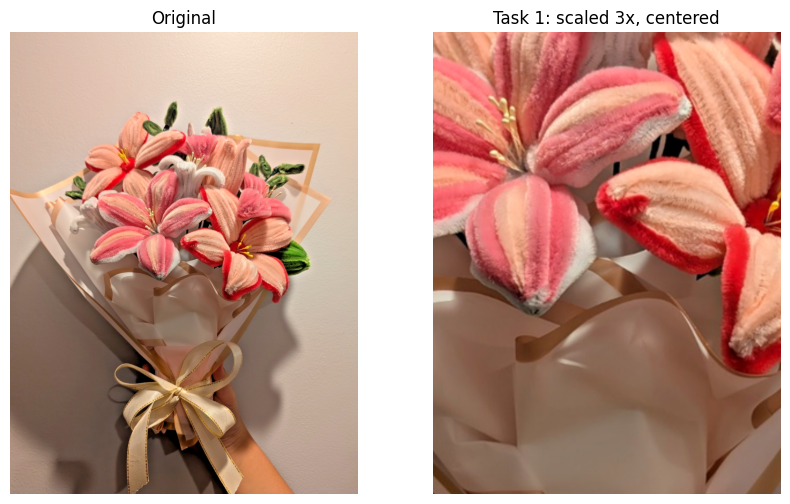

In [4]:
sx, sy = 3, 3
M = np.float32([[sx, 0, (1 - sx) * cx],
                [0, sy, (1 - sy) * cy]])
print("Scaling matrix:\n", M)

out1 = cv2.warpAffine(img, M, (w, h))
show(img, out1, "Task 1: scaled 3x, centered")

Tilted size: (1487, 1487) Fixed size: (2102, 2102)


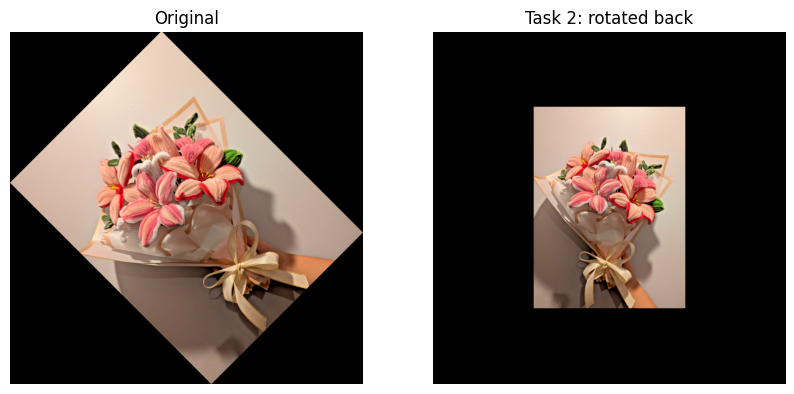

In [5]:
def rotate_bound(image, angle):
    h, w = image.shape[:2]
    cx, cy = w / 2, h / 2
    M = cv2.getRotationMatrix2D((cx, cy), angle, 1.0)
    cos, sin = abs(M[0, 0]), abs(M[0, 1])
    nw = int(h * sin + w * cos)
    nh = int(h * cos + w * sin)
    M[0, 2] += nw / 2 - cx
    M[1, 2] += nh / 2 - cy
    return cv2.warpAffine(image, M, (nw, nh)), (nw, nh)

tilted, size_t = rotate_bound(img, 45)      # simulate the satellite photo
fixed, size_f = rotate_bound(tilted, -45)   # spin back to "true north"
print("Tilted size:", size_t, "Fixed size:", size_f)

show(tilted, fixed, "Task 2: rotated back")

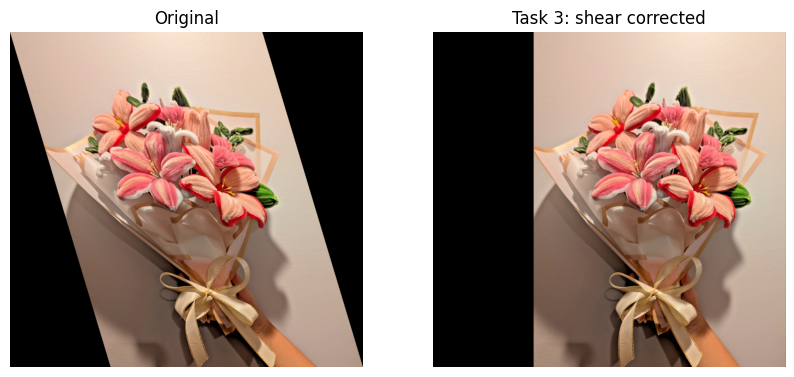

In [6]:
# create the slanted image (x' = x + k*y)
k = 0.3
M_slant = np.float32([[1, k, 0],
                      [0, 1, 0]])
slanted = cv2.warpAffine(img, M_slant, (int(w + k * h), h))

# undo it: inverse shear is x' = x - k*y, shifted so nothing falls off the left
hs, ws = slanted.shape[:2]
M_fix = np.float32([[1, -k, k * hs],
                    [0, 1, 0]])
fixed3 = cv2.warpAffine(slanted, M_fix, (ws, hs))

show(slanted, fixed3, "Task 3: shear corrected")

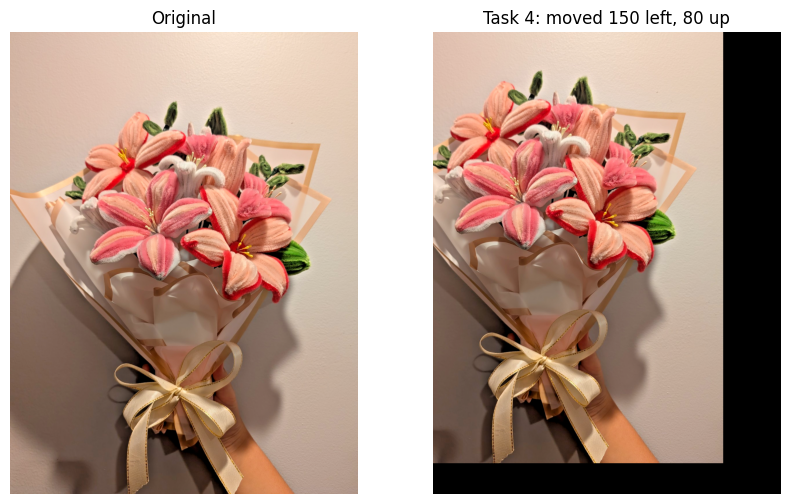

[[   1.    0. -150.]
 [   0.    1.  -80.]
 [   0.    0.    1.]]


In [7]:
M = np.float32([[1, 0, -150],
                [0, 1, -80]])
out4 = cv2.warpAffine(img, M, (w, h))
show(img, out4, "Task 4: moved 150 left, 80 up")

# the same thing as a 3x3 homogeneous matrix
T = np.array([[1, 0, -150],
              [0, 1, -80],
              [0, 0, 1]], dtype=np.float32)
print(T)

## Task 5 Onwards

Combined rigid matrix:
 [[   0.866    0.5   -179.51 ]
 [  -0.5      0.866  266.135]
 [   0.       0.       1.   ]]


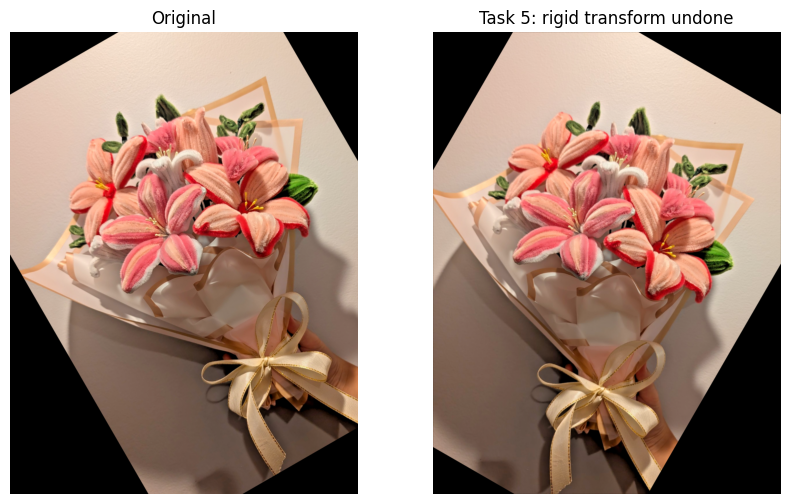

In [8]:
def to3x3(M2):
    """Turn a 2x3 matrix into 3x3 by adding the bottom row [0,0,1]."""
    return np.vstack([M2, [0, 0, 1]]).astype(np.float64)

def translation(tx, ty):
    return np.array([[1, 0, tx],
                     [0, 1, ty],
                     [0, 0, 1]], dtype=np.float64)

# rotation about the image center (positive angle = counterclockwise in OpenCV)
R = to3x3(cv2.getRotationMatrix2D((cx, cy), 30, 1.0))
T = translation(60, -40)

# create the "bad" chip: rotated sideways and off-center
M_bad = T @ R                      # rotate first, then translate
bad = cv2.warpAffine(img, M_bad[:2], (w, h))

# the fix: ONE matrix, the inverse of the combined transform
M_fix = np.linalg.inv(M_bad)
fixed5 = cv2.warpAffine(bad, M_fix[:2], (w, h))

print("Combined rigid matrix:\n", np.round(M_bad, 3))
show(bad, fixed5, "Task 5: rigid transform undone")

Similarity matrix:
 [[ 3.76000e-01  1.37000e-01 -2.93000e-01]
 [-1.37000e-01  3.76000e-01  7.36243e+02]
 [ 0.00000e+00  0.00000e+00  1.00000e+00]]


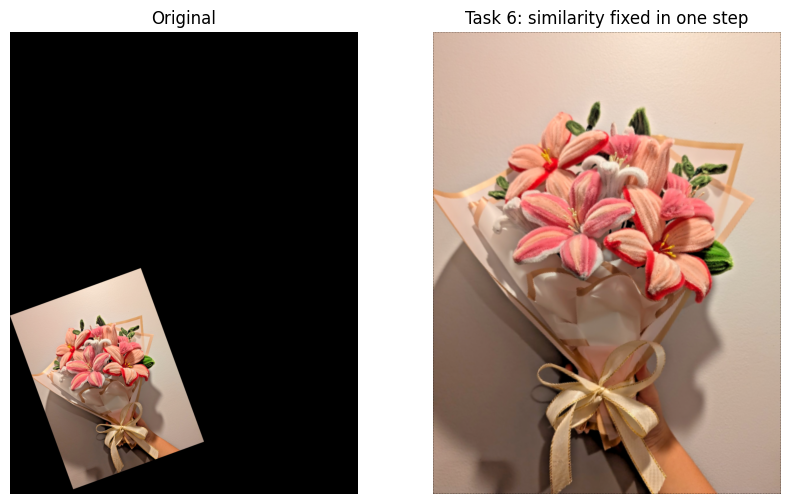

In [9]:
s = 0.4
S = np.array([[s, 0, (1 - s) * cx],      # scale about the center
              [0, s, (1 - s) * cy],
              [0, 0, 1]], dtype=np.float64)
R = to3x3(cv2.getRotationMatrix2D((cx, cy), 20, 1.0))
T = translation(-200, 300)               # push toward the wrong corner

M_bad = T @ R @ S                        # scale -> rotate -> translate
blueprint = cv2.warpAffine(img, M_bad[:2], (w, h))

M_fix = np.linalg.inv(M_bad)             # one matrix, one step
fixed6 = cv2.warpAffine(blueprint, M_fix[:2], (w, h))

print("Similarity matrix:\n", np.round(M_bad, 3))
show(blueprint, fixed6, "Task 6: similarity fixed in one step")

Manual:
 [[ 1.677900e+00  1.094000e-01 -2.101068e+02]
 [-1.697000e-01  1.292200e+00 -8.301070e+01]]
Same as OpenCV? True


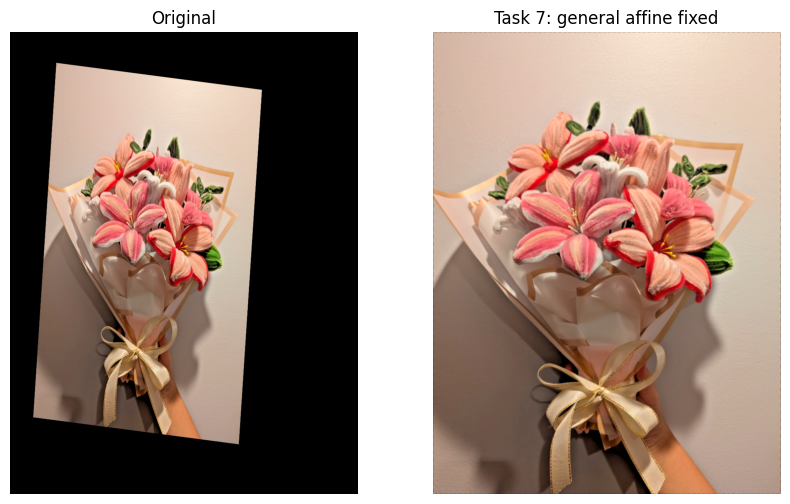

In [10]:
# 3 landmarks in the original image (must not lie on one straight line)
src3 = np.float32([[0, 0], [w - 1, 0], [0, h - 1]])

# where those landmarks ended up in the glitched photo (made-up values)
dst3 = np.float32([[120, 80], [w - 250, 150], [60, h - 200]])

# create the glitched image
M_glitch = cv2.getAffineTransform(src3, dst3)
glitched = cv2.warpAffine(img, M_glitch, (w, h))

# MANUAL solve for the 6 unknowns [a, b, tx, c, d, ty], going glitched -> original
def solve_affine(src, dst):
    A, B = [], []
    for (x, y), (xp, yp) in zip(src, dst):
        A += [[x, y, 1, 0, 0, 0],
              [0, 0, 0, x, y, 1]]
        B += [xp, yp]
    p = np.linalg.solve(np.array(A, dtype=np.float64), np.array(B, dtype=np.float64))
    return p.reshape(2, 3)

M_manual = solve_affine(dst3, src3)             # reversed: glitched -> original
M_cv = cv2.getAffineTransform(dst3, src3)       # OpenCV's version of the same thing
print("Manual:\n", np.round(M_manual, 4))
print("Same as OpenCV?", np.allclose(M_manual, M_cv, atol=1e-3))

fixed7 = cv2.warpAffine(glitched, M_manual.astype(np.float32), (w, h))
show(glitched, fixed7, "Task 7: general affine fixed")

H_fix:
 [[ 1.8328000e+00  4.4373000e-01 -5.2475884e+02]
 [ 0.0000000e+00  1.6591600e+00 -2.4887460e+02]
 [ 0.0000000e+00  1.4800000e-03  1.0000000e+00]]


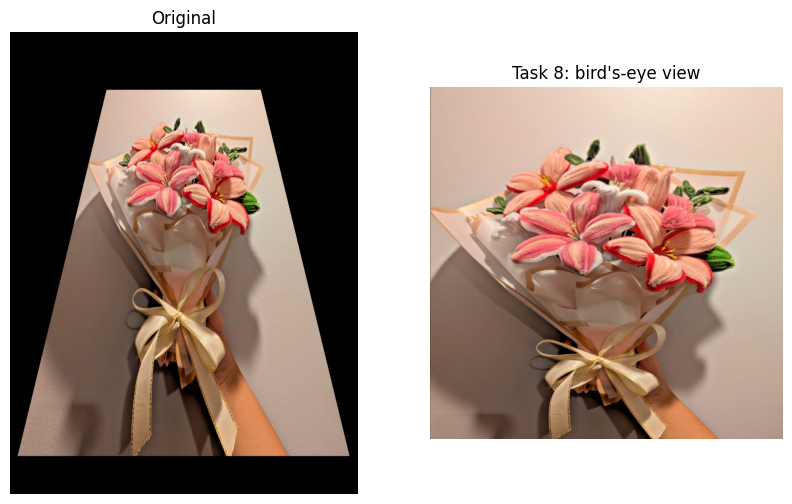

In [11]:
# original image corners (TL, TR, BR, BL)
src_rect = np.float32([[0, 0], [w-1, 0], [w-1, h-1], [0, h-1]])

# where those corners land in the "sidewalk photo": far (top) edge is narrower
bad_corners = np.float32([[250, 150], [650, 150], [880, 1100], [20, 1100]])

H_bad = cv2.getPerspectiveTransform(src_rect, bad_corners)
sidewalk = cv2.warpPerspective(img, H_bad, (w, h))

# FIX: take the 4 corners of the art in the photo -> a perfect square
side = 600
dst_sq = np.float32([[0, 0], [side, 0], [side, side], [0, side]])
H_fix = cv2.getPerspectiveTransform(bad_corners, dst_sq)
birdseye = cv2.warpPerspective(sidewalk, H_fix, (side, side))

print("H_fix:\n", np.round(H_fix, 5))
show(sidewalk, birdseye, "Task 8: bird's-eye view")

Homography:
 [[ 1.10710e+00 -0.00000e+00  3.00000e+02]
 [ 7.12000e-02  1.07150e+00 -4.28597e+01]
 [ 1.00000e-04 -0.00000e+00  1.00000e+00]]


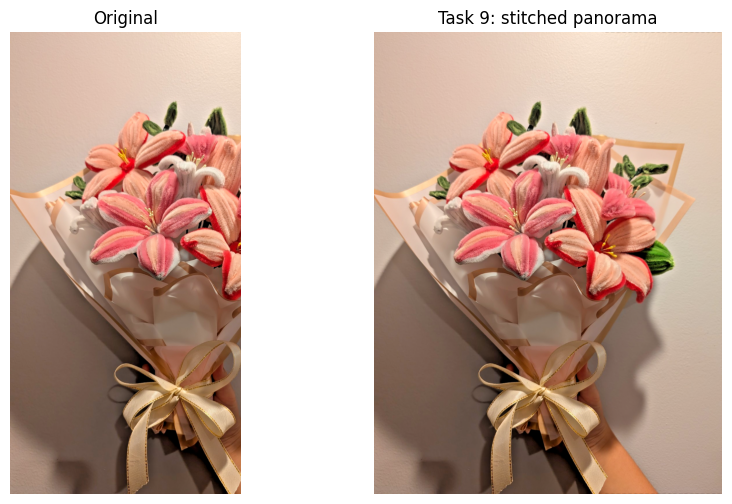

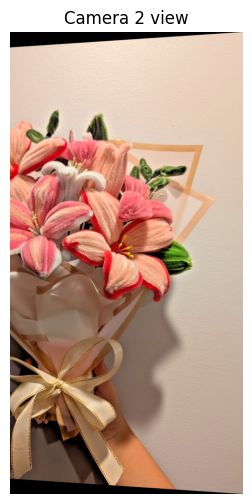

In [12]:
# simulate two cameras that overlap in x = 300..600
img1 = img[:, 0:600].copy()                  # camera 1 (left part)
img2_flat = img[:, 300:w].copy()             # camera 2 (right part)
h2, w2 = img2_flat.shape[:2]

# camera 2 looks from a slightly different angle (small perspective distortion)
c_src = np.float32([[0, 0], [w2-1, 0], [w2-1, h2-1], [0, h2-1]])
c_dst = np.float32([[0, 40], [w2-1, 0], [w2-1, h2-1], [0, h2-41]])
H_cam = cv2.getPerspectiveTransform(c_src, c_dst)
img2 = cv2.warpPerspective(img2_flat, H_cam, (w2, h2))

# 4 matching points in the overlap (coordinates in the original image)
orig_pts = np.float32([[320, 100], [580, 100], [580, 1100], [320, 1100]])
pts1 = orig_pts.copy()                                       # same coords in img1
pts2 = cv2.perspectiveTransform((orig_pts - [300, 0]).reshape(-1, 1, 2), H_cam).reshape(-1, 2)

# homography that maps img2 into img1's coordinate system
H, mask = cv2.findHomography(pts2, pts1, cv2.RANSAC)
print("Homography:\n", np.round(H, 4))

canvas = cv2.warpPerspective(img2, H, (w, h))
canvas[0:img1.shape[0], 0:img1.shape[1]] = img1

show(img1, canvas, "Task 9: stitched panorama")
plt.figure(figsize=(5, 6)); plt.imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)); plt.title("Camera 2 view"); plt.axis('off'); plt.show()

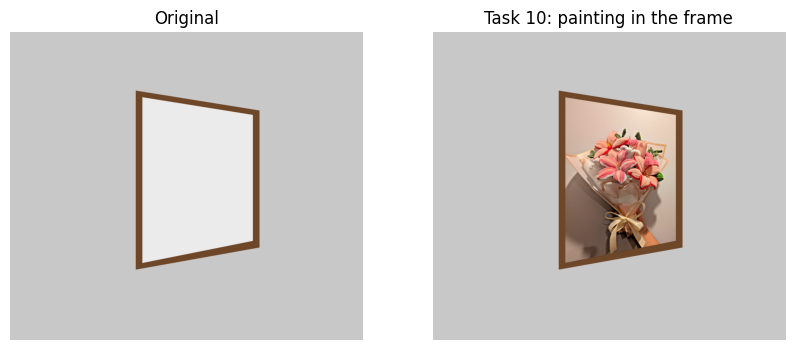

In [13]:
# empty angled picture frame on a wall
W, Hh = 1600, 1400
wall = np.full((Hh, W, 3), 200, np.uint8)
frame_corners = np.float32([[600, 300], [1100, 380], [1100, 950], [600, 1050]])
outer = np.int32([[570, 270], [1130, 360], [1130, 980], [570, 1080]])
cv2.fillPoly(wall, [outer], (40, 70, 110))                 # wooden frame
cv2.fillPoly(wall, [frame_corners.astype(np.int32)], (235, 235, 235))  # empty opening

painting = img
pc = np.float32([[0, 0], [w-1, 0], [w-1, h-1], [0, h-1]])

# 1) linear scale  2) rigid (rotate + translate)
s = 0.5
S = np.diag([s, s, 1.0])
R = to3x3(cv2.getRotationMatrix2D((cx*s, cy*s), 5, 1.0))
T = translation(550, 250)
M_lin = T @ R @ S

# where the painting corners are after steps 1-2
pc_after = cv2.perspectiveTransform(pc.reshape(-1, 1, 2), M_lin).reshape(-1, 2).astype(np.float32)

# 3) projective: those 4 corners -> the angled frame's 4 corners
H_proj = cv2.getPerspectiveTransform(pc_after, frame_corners)
H_total = H_proj @ M_lin                                   # ONE matrix does everything

warped = cv2.warpPerspective(painting, H_total, (W, Hh))
mask = cv2.warpPerspective(np.full((h, w), 255, np.uint8), H_total, (W, Hh))
result = wall.copy()
result[mask > 0] = warped[mask > 0]

show(wall, result, "Task 10: painting in the frame")